In [43]:


import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import csv

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

IMG_SIZE = 32
N_CHANNELS = 1
N_CLASSES = 33

# Vérifications
assert IMG_SIZE == 32
assert N_CHANNELS == 1
assert N_CLASSES == 33


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch :", torch.__version__)
print("Device  :", device)
print("Image   :", f"{IMG_SIZE}x{IMG_SIZE}x{N_CHANNELS}")
print("Classes :", N_CLASSES)

PyTorch : 2.14.1+cpu
Device  : cpu
Image   : 32x32x1
Classes : 33


In [3]:

# Dimensions d'entrée
H, W = IMG_SIZE, IMG_SIZE

assert H == 32 and W == 32, "L'image d'entrée doit être 32x32"

# C1 : convolution 5x5, stride=1, padding=0
H_C1 = H - 5 + 1
W_C1 = W - 5 + 1

assert H_C1 == 28
assert W_C1 == 28

# S2 : average pooling 2x2, stride=2
H_S2 = H_C1 // 2
W_S2 = W_C1 // 2

assert H_S2 == 14
assert W_S2 == 14

# C3 : convolution 5x5
H_C3 = H_S2 - 5 + 1
W_C3 = W_S2 - 5 + 1

assert H_C3 == 10
assert W_C3 == 10

# S4 : average pooling 2x2
H_S4 = H_C3 // 2
W_S4 = W_C3 // 2

assert H_S4 == 5
assert W_S4 == 5

# Flatten
FLATTEN_SIZE = 16 * H_S4 * W_S4

assert FLATTEN_SIZE == 400

# Architecture fully connected
assert 400 == 16 * 5 * 5
assert N_CLASSES == 33

print(" Entrée      :", H, "x", W)
print(" C1          : 6 x", H_C1, "x", W_C1)
print(" S2          : 6 x", H_S2, "x", W_S2)
print(" C3          : 16 x", H_C3, "x", W_C3)
print(" S4          : 16 x", H_S4, "x", W_S4)
print(" Flatten      :", FLATTEN_SIZE)
print(" C5           : 400 -> 120")
print(" F6           : 120 -> 84")
print(" Output       : 84 ->", N_CLASSES)


 Entrée      : 32 x 32
 C1          : 6 x 28 x 28
 S2          : 6 x 14 x 14
 C3          : 16 x 10 x 10
 S4          : 16 x 5 x 5
 Flatten      : 400
 C5           : 400 -> 120
 F6           : 120 -> 84
 Output       : 84 -> 33


In [5]:


class LeNet5(nn.Module):
    def __init__(
        self,
        num_classes=33,
        in_channels=1,
        conv1_channels=6,
        conv2_channels=16,
        fc1_size=120,
        fc2_size=84,
        kernel_size=5,
        pool_size=2
    ):
        super().__init__()

        # C1 : Convolution
      
        self.conv1 = nn.Conv2d(
            in_channels=in_channels,
            out_channels=conv1_channels,
            kernel_size=kernel_size,
            stride=1,
            padding=0
        )

        # S2 : Average Pooling
       
        self.pool1 = nn.AvgPool2d(
            kernel_size=pool_size,
            stride=2
        )

        # C3 : Convolution
       
        self.conv2 = nn.Conv2d(
            in_channels=conv1_channels,
            out_channels=conv2_channels,
            kernel_size=kernel_size,
            stride=1,
            padding=0
        )

        # S4 : Average Pooling
     
        self.pool2 = nn.AvgPool2d(
            kernel_size=pool_size,
            stride=2
        )

        # C5 : Fully Connected
       
        self.fc1 = nn.Linear(
            conv2_channels * 5 * 5,
            fc1_size
        )

        # F6 : Fully Connected
       
        self.fc2 = nn.Linear(
            fc1_size,
            fc2_size
        )

        
        # Output : 33 classes
      
        self.output = nn.Linear(
            fc2_size,
            num_classes
        )

    def forward(self, x):

        # C1 + activation
        x = self.conv1(x)
        x = F.tanh(x)

        # S2
        x = self.pool1(x)

        # C3 + activation
        x = self.conv2(x)
        x = F.tanh(x)

        # S4
        x = self.pool2(x)

        # Flatten
        x = torch.flatten(x, start_dim=1)

        # C5
        x = self.fc1(x)
        x = F.tanh(x)

        # F6
        x = self.fc2(x)
        x = F.tanh(x)

        # Output
        x = self.output(x)

        return x

In [7]:

# Test du forward pass


# Création d'un batch fictif de 4 images
x_test = torch.randn(4, 1, 32, 32)

# Création du modèle
model = LeNet5(
    num_classes=N_CLASSES,
    in_channels=N_CHANNELS
).to(device)

# Forward pass
with torch.no_grad():
    output = model(x_test.to(device))

# Assertions


assert x_test.shape == (4, 1, 32, 32)
assert output.shape == (4, 33)

assert torch.isfinite(output).all(), \
    "La sortie contient des valeurs NaN ou infinies."

print("Input shape  :", x_test.shape)
print("Output shape :", output.shape)



Input shape  : torch.Size([4, 1, 32, 32])
Output shape : torch.Size([4, 33])


In [10]:

# Chemins du dataset


DATASET_DIR = os.path.join("AMHCD_64", "AMHCD_64")
LABELS_DIR = os.path.join("labels", "labels")

print("Dataset :", os.path.abspath(DATASET_DIR))
print("Labels  :", os.path.abspath(LABELS_DIR))

assert os.path.isdir(DATASET_DIR), "Dossier dataset introuvable."
assert os.path.isdir(LABELS_DIR), "Dossier labels introuvable."


Dataset : C:\Users\hp\Desktop\leNET5\AMHCD_64\AMHCD_64
Labels  : C:\Users\hp\Desktop\leNET5\labels\labels


In [12]:
# ============================================================
# Lecture des classes du dataset
# ============================================================

class_dirs = sorted([
    d for d in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, d))
])

print("Nombre de classes trouvées :", len(class_dirs))
print("Classes :", class_dirs)

# Vérification du nombre de classes
assert len(class_dirs) == N_CLASSES, (
    f"On attend {N_CLASSES} classes, "
    f"mais {len(class_dirs)} ont été trouvées."
)


Nombre de classes trouvées : 33
Classes : ['ya', 'yab', 'yach', 'yad', 'yadd', 'yae', 'yaf', 'yag', 'yagh', 'yagw', 'yah', 'yahh', 'yaj', 'yak', 'yakw', 'yal', 'yam', 'yan', 'yaq', 'yar', 'yarr', 'yas', 'yass', 'yat', 'yatt', 'yaw', 'yax', 'yay', 'yaz', 'yazz', 'yey', 'yi', 'yu']


In [14]:

# Mapping des classes vers des labels numériques

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(class_dirs)
}

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

# Vérifications
assert len(class_to_idx) == 33
assert len(idx_to_class) == 33
assert set(class_to_idx.values()) == set(range(33))

print("Mapping classes → labels :\n")

for class_name, idx in class_to_idx.items():
    print(f"{idx:2d} → {class_name}")



Mapping classes → labels :

 0 → ya
 1 → yab
 2 → yach
 3 → yad
 4 → yadd
 5 → yae
 6 → yaf
 7 → yag
 8 → yagh
 9 → yagw
10 → yah
11 → yahh
12 → yaj
13 → yak
14 → yakw
15 → yal
16 → yam
17 → yan
18 → yaq
19 → yar
20 → yarr
21 → yas
22 → yass
23 → yat
24 → yatt
25 → yaw
26 → yax
27 → yay
28 → yaz
29 → yazz
30 → yey
31 → yi
32 → yu


In [16]:

# Dataset Tifinagh personnalisé


class TifinaghDataset(Dataset):

    def __init__(self, image_paths, labels, img_size=32):
        self.image_paths = image_paths
        self.labels = labels
        self.img_size = img_size

        # Vérifications
        assert len(self.image_paths) == len(self.labels)
        assert self.img_size == 32

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        # Lire l'image
        image = Image.open(self.image_paths[idx])

        # Conversion en niveaux de gris
        image = image.convert("L")

        # Redimensionnement
        image = image.resize((self.img_size, self.img_size))

        # Conversion en tableau NumPy
        image = np.array(image, dtype=np.float32)

        # Normalisation [0,255] -> [0,1]
        image = image / 255.0

        # Ajouter la dimension channel
        image = np.expand_dims(image, axis=0)

        # Conversion en Tensor
        image = torch.tensor(image, dtype=torch.float32)

        # Label
        label = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        # Assertions
        assert image.shape == (1, 32, 32)
        assert 0.0 <= image.min() <= 1.0
        assert 0.0 <= image.max() <= 1.0
        assert 0 <= label.item() < N_CLASSES

        return image, label

In [18]:

image_paths = []
image_labels = []

valid_extensions = (".jpg", ".jpeg", ".png")

for class_name in class_dirs:

    class_path = os.path.join(DATASET_DIR, class_name)
    class_idx = class_to_idx[class_name]

    for filename in os.listdir(class_path):

        if filename.lower().endswith(valid_extensions):

            image_path = os.path.join(class_path, filename)

            image_paths.append(image_path)
            image_labels.append(class_idx)

# Vérifications
assert len(image_paths) > 0
assert len(image_paths) == len(image_labels)
assert all(0 <= label < N_CLASSES for label in image_labels)

print("Nombre total d'images :", len(image_paths))
print("Nombre total de labels :", len(image_labels))



Nombre total d'images : 25740
Nombre total de labels : 25740


In [20]:

# Train / Validation / Test split


X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=image_labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

# Assertions
assert len(X_train) + len(X_val) + len(X_test) == len(image_paths)
assert len(y_train) == len(X_train)
assert len(y_val) == len(X_val)
assert len(y_test) == len(X_test)

assert set(y_train) == set(range(N_CLASSES))
assert set(y_val) == set(range(N_CLASSES))
assert set(y_test) == set(range(N_CLASSES))

print(f"Train      : {len(X_train)} images")
print(f"Validation : {len(X_val)} images")
print(f"Test       : {len(X_test)} images")


Train      : 18018 images
Validation : 3861 images
Test       : 3861 images


In [22]:
# ============================================================
# Création des datasets et DataLoaders
# ============================================================

BATCH_SIZE = 64

train_dataset = TifinaghDataset(X_train, y_train, IMG_SIZE)
val_dataset   = TifinaghDataset(X_val, y_val, IMG_SIZE)
test_dataset  = TifinaghDataset(X_test, y_test, IMG_SIZE)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Vérifications
images, labels = next(iter(train_loader))

assert images.shape == (BATCH_SIZE, 1, 32, 32)
assert labels.shape == (BATCH_SIZE,)
assert images.dtype == torch.float32
assert labels.dtype == torch.long
assert images.min() >= 0.0
assert images.max() <= 1.0
assert labels.min() >= 0
assert labels.max() < N_CLASSES

print("Batch images :", images.shape)
print("Batch labels :", labels.shape)
print("Image range  :", images.min().item(), "→", images.max().item())


Batch images : torch.Size([64, 1, 32, 32])
Batch labels : torch.Size([64])
Image range  : 0.24705882370471954 → 1.0


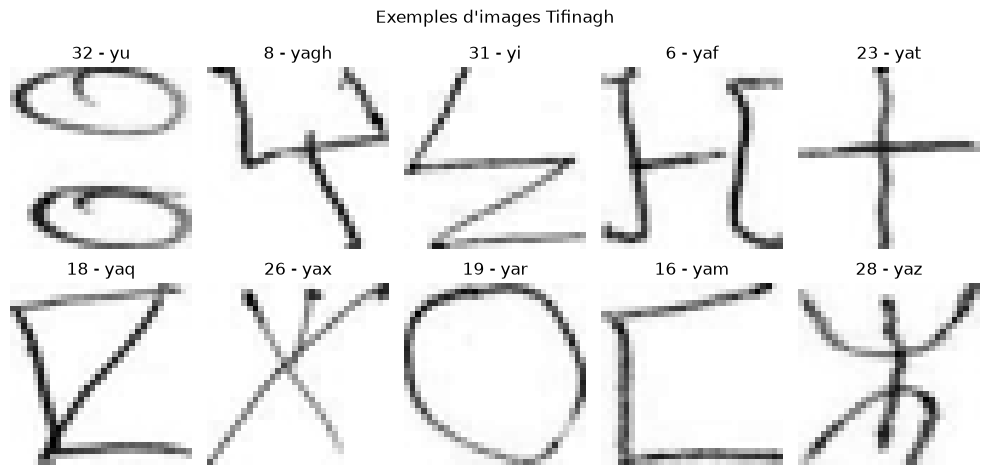

In [23]:

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(
        f"{labels[i].item()} - {idx_to_class[labels[i].item()]}"
    )
    ax.axis("off")

plt.suptitle("Exemples d'images Tifinagh")
plt.tight_layout()
plt.show()

In [25]:


LEARNING_RATE = 0.001
EPOCHS = 10

# Modèle
model = LeNet5(
    num_classes=N_CLASSES,
    in_channels=N_CHANNELS
).to(device)

# Fonction de perte
criterion = nn.CrossEntropyLoss()

# Optimiseur initial : Adam
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Vérifications
assert LEARNING_RATE > 0
assert EPOCHS > 0
assert isinstance(criterion, nn.CrossEntropyLoss)

print("Loss      :", criterion)
print("Optimizer : Adam")
print("LR        :", LEARNING_RATE)
print("Epochs    :", EPOCHS)


Loss      : CrossEntropyLoss()
Optimizer : Adam
LR        : 0.001
Epochs    : 10


In [26]:

# Fonctions d'entraînement et d'évaluation


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    assert total > 0

    return total_loss / total, correct / total


def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    assert total > 0

    return total_loss / total, correct / total


def train_model(model, train_loader, val_loader,
                criterion, optimizer, epochs, device):

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):

        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )

        val_loss, val_acc = evaluate(
            model, val_loader, criterion, device
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch [{epoch+1:02d}/{epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

    # Vérifications finales
    assert len(history["train_loss"]) == epochs
    assert len(history["train_acc"]) == epochs
    assert len(history["val_loss"]) == epochs
    assert len(history["val_acc"]) == epochs

    return history

# Entraînement


history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=EPOCHS,
    device=device
)



Epoch [01/10] | Train Loss: 2.0846 | Train Acc: 0.4611 | Val Loss: 0.8995 | Val Acc: 0.7897
Epoch [02/10] | Train Loss: 0.6346 | Train Acc: 0.8494 | Val Loss: 0.4793 | Val Acc: 0.8845
Epoch [03/10] | Train Loss: 0.4114 | Train Acc: 0.8963 | Val Loss: 0.3725 | Val Acc: 0.9003
Epoch [04/10] | Train Loss: 0.3118 | Train Acc: 0.9199 | Val Loss: 0.3123 | Val Acc: 0.9156
Epoch [05/10] | Train Loss: 0.2548 | Train Acc: 0.9336 | Val Loss: 0.2471 | Val Acc: 0.9306
Epoch [06/10] | Train Loss: 0.2066 | Train Acc: 0.9469 | Val Loss: 0.2135 | Val Acc: 0.9391
Epoch [07/10] | Train Loss: 0.1756 | Train Acc: 0.9543 | Val Loss: 0.1861 | Val Acc: 0.9464
Epoch [08/10] | Train Loss: 0.1461 | Train Acc: 0.9621 | Val Loss: 0.1727 | Val Acc: 0.9529
Epoch [09/10] | Train Loss: 0.1250 | Train Acc: 0.9670 | Val Loss: 0.1615 | Val Acc: 0.9536
Epoch [10/10] | Train Loss: 0.1068 | Train Acc: 0.9737 | Val Loss: 0.1415 | Val Acc: 0.9599


===== TEST FINAL =====
Test Loss     : 0.1491
Test Accuracy : 0.9575
Test Accuracy : 95.75%


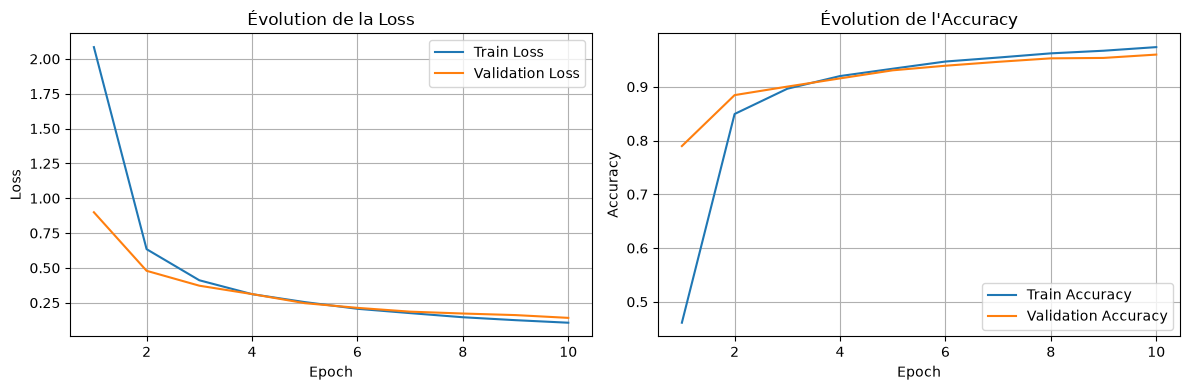

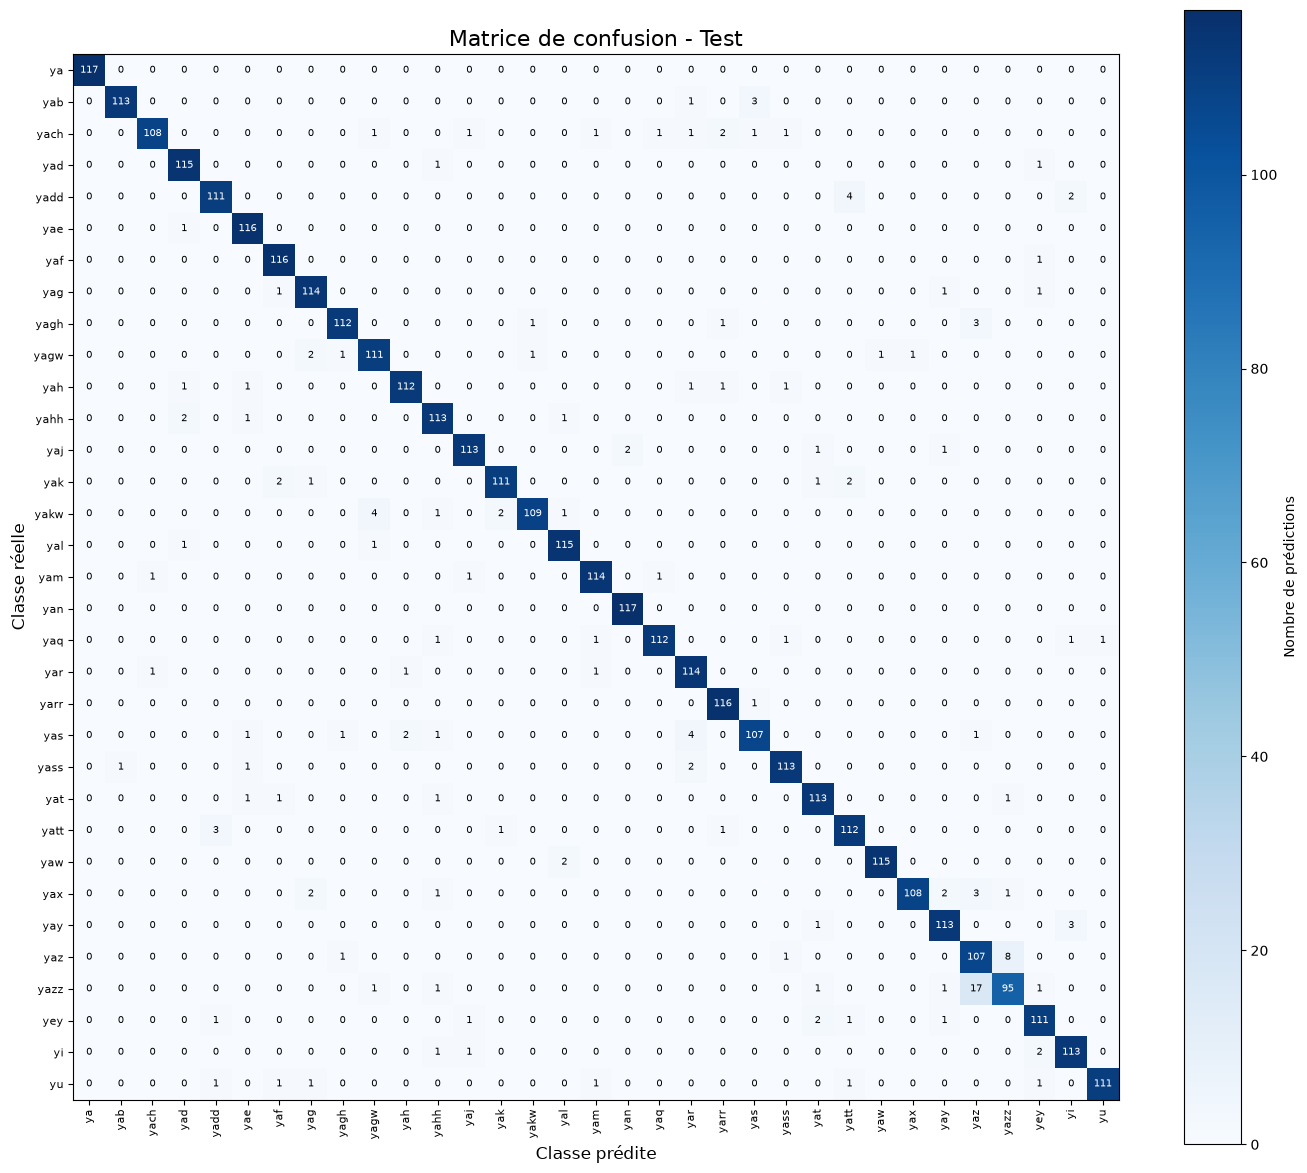


===== CLASSIFICATION REPORT =====

              precision    recall  f1-score   support

          ya       1.00      1.00      1.00       117
         yab       0.99      0.97      0.98       117
        yach       0.98      0.92      0.95       117
         yad       0.96      0.98      0.97       117
        yadd       0.96      0.95      0.95       117
         yae       0.96      0.99      0.97       117
         yaf       0.96      0.99      0.97       117
         yag       0.95      0.97      0.96       117
        yagh       0.97      0.96      0.97       117
        yagw       0.94      0.95      0.94       117
         yah       0.97      0.96      0.97       117
        yahh       0.93      0.97      0.95       117
         yaj       0.97      0.97      0.97       117
         yak       0.97      0.95      0.96       117
        yakw       0.98      0.93      0.96       117
         yal       0.97      0.98      0.97       117
         yam       0.97      0.97      0.97  

In [28]:

# Évaluation finale sur le test set
# + Courbes Loss/Accuracy
# + Matrice de confusion

# 1. Test

test_loss, test_acc = evaluate(
    model,
    test_loader,
    criterion,
    device
)

assert 0.0 <= test_acc <= 1.0
assert test_loss >= 0.0

print("===== TEST FINAL =====")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f}")
print(f"Test Accuracy : {test_acc * 100:.2f}%")


# 2. Courbes d'apprentissage


epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epochs_range,
    history["train_loss"],
    label="Train Loss"
)
axes[0].plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Évolution de la Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epochs_range,
    history["train_acc"],
    label="Train Accuracy"
)
axes[1].plot(
    epochs_range,
    history["val_acc"],
    label="Validation Accuracy"
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Évolution de l'Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


# 3. Prédictions test


all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

assert len(all_predictions) == len(all_labels)
assert len(all_predictions) == len(test_dataset)




# 4. Matrice de confusion



cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(N_CLASSES))
)

assert cm.shape == (N_CLASSES, N_CLASSES)

plt.figure(figsize=(14, 12))

plt.imshow(
    cm,
    interpolation="nearest",
    cmap="Blues"
)

plt.title("Matrice de confusion - Test", fontsize=16)
plt.xlabel("Classe prédite", fontsize=12)
plt.ylabel("Classe réelle", fontsize=12)

plt.colorbar(label="Nombre de prédictions")

# Noms des classes
class_names = [
    idx_to_class[i] for i in range(N_CLASSES)
]

plt.xticks(
    range(N_CLASSES),
    class_names,
    rotation=90,
    fontsize=8
)

plt.yticks(
    range(N_CLASSES),
    class_names,
    fontsize=8
)

# Affichage des valeurs dans chaque case
threshold = cm.max() / 2

for i in range(N_CLASSES):
    for j in range(N_CLASSES):

        value = cm[i, j]

        plt.text(
            j,
            i,
            str(value),
            ha="center",
            va="center",
            fontsize=7,
            color="white" if value > threshold else "black"
        )

plt.tight_layout()
plt.show()

# 5. Rapport de classification


print("\n===== CLASSIFICATION REPORT =====\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(N_CLASSES)),
        target_names=[
            idx_to_class[i] for i in range(N_CLASSES)
        ],
        zero_division=0
    )
)



Image originale : torch.Size([1, 32, 32])
Feature Maps C1 : torch.Size([1, 6, 28, 28])
Feature Maps C3 : torch.Size([1, 16, 10, 10])

Classe réelle : 3 → yad


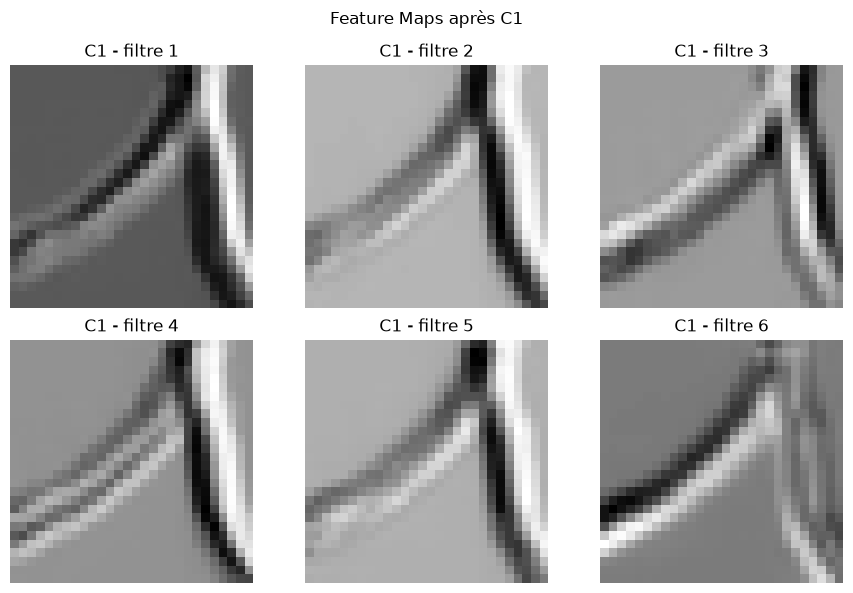

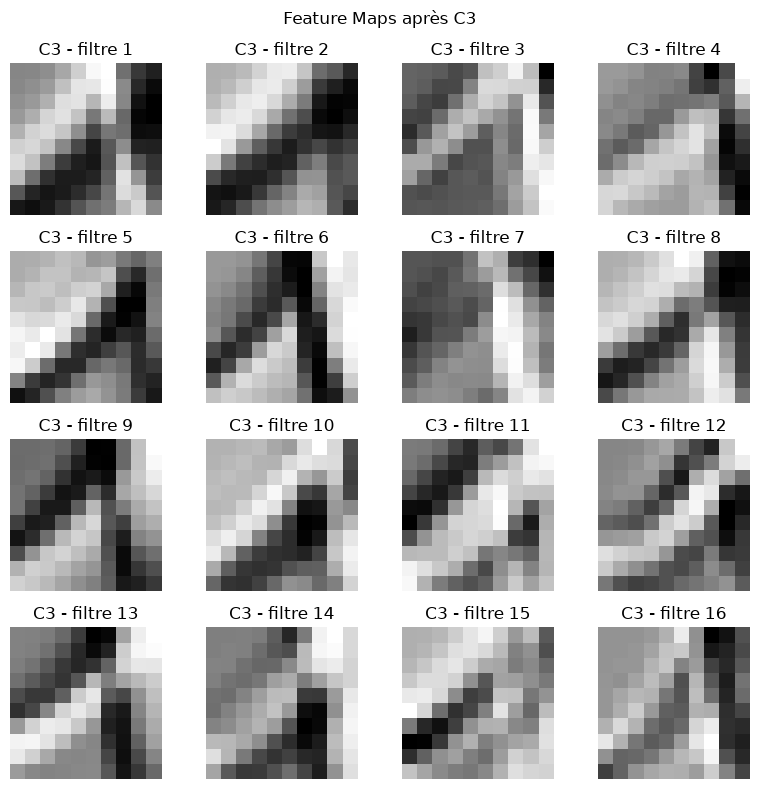

In [29]:

# Visualisation des Feature Maps

# Prendre une image du test set
image, label = test_dataset[0]

x = image.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    # C1
    c1 = model.conv1(x)
    a1 = F.tanh(c1)
    s2 = model.pool1(a1)

    # C3
    c3 = model.conv2(s2)
    a3 = F.tanh(c3)
    s4 = model.pool2(a3)

# Assertions
assert c1.shape == (1, 6, 28, 28)
assert a1.shape == (1, 6, 28, 28)
assert s2.shape == (1, 6, 14, 14)

assert c3.shape == (1, 16, 10, 10)
assert a3.shape == (1, 16, 10, 10)
assert s4.shape == (1, 16, 5, 5)

print("Image originale :", image.shape)
print("Feature Maps C1 :", c1.shape)
print("Feature Maps C3 :", c3.shape)

print(
    "\nClasse réelle :",
    label.item(),
    "→",
    idx_to_class[label.item()]
)

# Feature maps C1

fig, axes = plt.subplots(2, 3, figsize=(9, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(a1[0, i].cpu(), cmap="gray")
    ax.set_title(f"C1 - filtre {i+1}")
    ax.axis("off")

plt.suptitle("Feature Maps après C1")
plt.tight_layout()
plt.show()

# Feature maps C3

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(a3[0, i].cpu(), cmap="gray")
    ax.set_title(f"C3 - filtre {i+1}")
    ax.axis("off")

plt.suptitle("Feature Maps après C3")
plt.tight_layout()
plt.show()


In [31]:

# Optimiseur SGD 
class CustomSGD:

    def __init__(self, parameters, lr=0.001):
        self.parameters = list(parameters)
        self.lr = lr

        assert self.lr > 0
        assert len(self.parameters) > 0

    def zero_grad(self):
        for param in self.parameters:
            if param.grad is not None:
                param.grad.zero_()

    def step(self):
        with torch.no_grad():
            for param in self.parameters:
                if param.grad is not None:
                    param -= self.lr * param.grad


# Test de l'optimiseur
custom_sgd = CustomSGD(
    model.parameters(),
    lr=0.001
)

assert custom_sgd.lr == 0.001
assert len(custom_sgd.parameters) > 0

print("Learning rate :", custom_sgd.lr)
print("Nombre de paramètres :", len(custom_sgd.parameters))

Learning rate : 0.001
Nombre de paramètres : 10


In [32]:

# Optimiseur Adam 
class CustomAdam:

    def __init__(
        self,
        parameters,
        lr=0.001,
        beta1=0.9,
        beta2=0.999,
        eps=1e-8
    ):
        self.parameters = list(parameters)

        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps

        self.t = 0

        self.m = [
            torch.zeros_like(param)
            for param in self.parameters
        ]

        self.v = [
            torch.zeros_like(param)
            for param in self.parameters
        ]

        assert self.lr > 0
        assert 0 < self.beta1 < 1
        assert 0 < self.beta2 < 1
        assert self.eps > 0
        assert len(self.parameters) > 0
        assert len(self.m) == len(self.parameters)
        assert len(self.v) == len(self.parameters)

    def zero_grad(self):
        for param in self.parameters:
            if param.grad is not None:
                param.grad.zero_()

    def step(self):

        self.t += 1

        with torch.no_grad():

            for i, param in enumerate(self.parameters):

                if param.grad is None:
                    continue

                grad = param.grad

                # Moments
                self.m[i] = (
                    self.beta1 * self.m[i]
                    + (1 - self.beta1) * grad
                )

                self.v[i] = (
                    self.beta2 * self.v[i]
                    + (1 - self.beta2) * grad * grad
                )

                # Correction du biais
                m_hat = self.m[i] / (
                    1 - self.beta1 ** self.t
                )

                v_hat = self.v[i] / (
                    1 - self.beta2 ** self.t
                )

                # Mise à jour Adam
                param -= self.lr * m_hat / (
                    torch.sqrt(v_hat) + self.eps
                )


# Test
custom_adam = CustomAdam(
    model.parameters(),
    lr=0.001
)

assert custom_adam.lr == 0.001
assert custom_adam.beta1 == 0.9
assert custom_adam.beta2 == 0.999
assert custom_adam.eps == 1e-8
assert custom_adam.t == 0
assert len(custom_adam.parameters) == 10

print("Learning rate :", custom_adam.lr)
print("Beta1 :", custom_adam.beta1)
print("Beta2 :", custom_adam.beta2)
print("Epsilon :", custom_adam.eps)
print("Nombre de paramètres :", len(custom_adam.parameters))

Learning rate : 0.001
Beta1 : 0.9
Beta2 : 0.999
Epsilon : 1e-08
Nombre de paramètres : 10


Epoch [01/5] | Train Loss: 3.4993 | Train Acc: 0.0250 | Val Loss: 3.4990 | Val Acc: 0.0298
Epoch [02/5] | Train Loss: 3.4988 | Train Acc: 0.0291 | Val Loss: 3.4986 | Val Acc: 0.0300
Epoch [03/5] | Train Loss: 3.4985 | Train Acc: 0.0301 | Val Loss: 3.4982 | Val Acc: 0.0303
Epoch [04/5] | Train Loss: 3.4981 | Train Acc: 0.0304 | Val Loss: 3.4979 | Val Acc: 0.0306
Epoch [05/5] | Train Loss: 3.4978 | Train Acc: 0.0308 | Val Loss: 3.4977 | Val Acc: 0.0316

===== SGD FINAL =====
Test Loss     : 3.4977
Test Accuracy : 0.0326
Test Accuracy : 3.26%


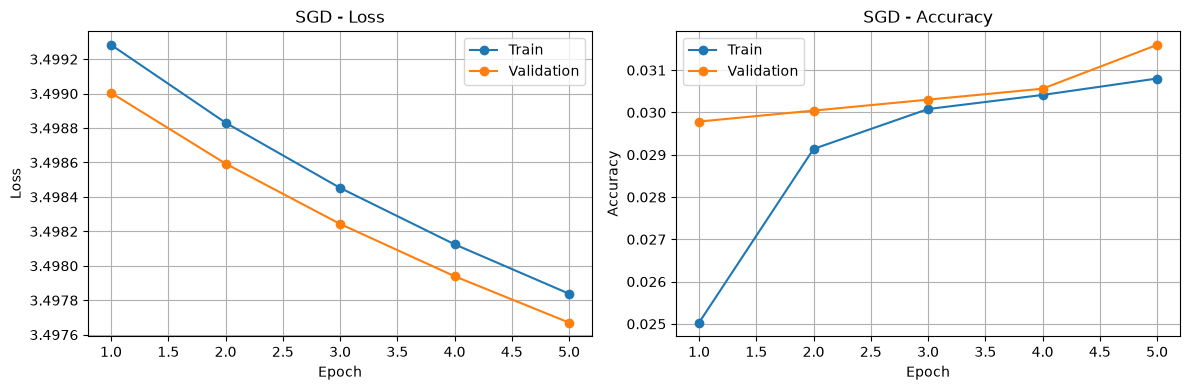

In [33]:


SGD_EPOCHS = 5
SGD_LR = 0.001

model_sgd = LeNet5(
    num_classes=N_CLASSES,
    in_channels=N_CHANNELS
).to(device)

criterion_sgd = nn.CrossEntropyLoss()

optimizer_sgd = CustomSGD(
    model_sgd.parameters(),
    lr=SGD_LR
)

# Entraînement
history_sgd = train_model(
    model=model_sgd,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_sgd,
    optimizer=optimizer_sgd,
    epochs=SGD_EPOCHS,
    device=device
)

# Test
test_loss_sgd, test_acc_sgd = evaluate(
    model_sgd,
    test_loader,
    criterion_sgd,
    device
)

# Assertions
assert len(history_sgd["train_loss"]) == SGD_EPOCHS
assert len(history_sgd["val_loss"]) == SGD_EPOCHS
assert 0 <= test_acc_sgd <= 1

print("\n===== SGD FINAL =====")
print(f"Test Loss     : {test_loss_sgd:.4f}")
print(f"Test Accuracy : {test_acc_sgd:.4f}")
print(f"Test Accuracy : {test_acc_sgd * 100:.2f}%")

# Courbes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

epochs_sgd = range(1, SGD_EPOCHS + 1)

axes[0].plot(
    epochs_sgd,
    history_sgd["train_loss"],
    marker="o",
    label="Train"
)
axes[0].plot(
    epochs_sgd,
    history_sgd["val_loss"],
    marker="o",
    label="Validation"
)
axes[0].set_title("SGD - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epochs_sgd,
    history_sgd["train_acc"],
    marker="o",
    label="Train"
)
axes[1].plot(
    epochs_sgd,
    history_sgd["val_acc"],
    marker="o",
    label="Validation"
)
axes[1].set_title("SGD - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()



In [35]:

# Nouvelle expérience SGD avec learning rate = 0.01


SGD_LR = 0.01
SGD_EPOCHS = 5

# Nouveau modèle avec initialisation aléatoire
model_sgd = LeNet5(
    num_classes=N_CLASSES,
    in_channels=N_CHANNELS
).to(device)

criterion_sgd = nn.CrossEntropyLoss()

optimizer_sgd = CustomSGD(
    model_sgd.parameters(),
    lr=SGD_LR
)

history_sgd = train_model(
    model=model_sgd,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_sgd,
    optimizer=optimizer_sgd,
    epochs=SGD_EPOCHS,
    device=device
)

test_loss_sgd, test_acc_sgd = evaluate(
    model_sgd,
    test_loader,
    criterion_sgd,
    device
)

assert np.isfinite(test_loss_sgd)
assert np.isfinite(test_acc_sgd)
assert 0 <= test_acc_sgd <= 1

print("\n===== SGD (LR = 0.01) =====")
print(f"Test Loss     : {test_loss_sgd:.4f}")
print(f"Test Accuracy : {test_acc_sgd * 100:.2f}%")

Epoch [01/5] | Train Loss: 3.4991 | Train Acc: 0.0265 | Val Loss: 3.4970 | Val Acc: 0.0295
Epoch [02/5] | Train Loss: 3.4962 | Train Acc: 0.0282 | Val Loss: 3.4949 | Val Acc: 0.0303
Epoch [03/5] | Train Loss: 3.4944 | Train Acc: 0.0313 | Val Loss: 3.4931 | Val Acc: 0.0458
Epoch [04/5] | Train Loss: 3.4925 | Train Acc: 0.0465 | Val Loss: 3.4911 | Val Acc: 0.0567
Epoch [05/5] | Train Loss: 3.4903 | Train Acc: 0.0527 | Val Loss: 3.4886 | Val Acc: 0.0640

===== SGD (LR = 0.01) =====
Test Loss     : 3.4884
Test Accuracy : 6.66%


In [37]:
# LeNet-5 +  Custom  Adam


ADAM_EPOCHS = 5
ADAM_LR = 0.001

# Nouveau modèle
model_adam = LeNet5(
    num_classes=N_CLASSES,
    in_channels=N_CHANNELS
).to(device)

criterion_adam = nn.CrossEntropyLoss()

optimizer_adam = CustomAdam(
    model_adam.parameters(),
    lr=ADAM_LR
)

# Entraînement
history_adam = train_model(
    model=model_adam,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_adam,
    optimizer=optimizer_adam,
    epochs=ADAM_EPOCHS,
    device=device
)

# Évaluation finale
test_loss_adam, test_acc_adam = evaluate(
    model_adam,
    test_loader,
    criterion_adam,
    device
)

assert len(history_adam["train_loss"]) == ADAM_EPOCHS
assert np.isfinite(test_loss_adam)
assert 0 <= test_acc_adam <= 1

print("\n===== CUSTOM ADAM FINAL =====")
print(f"Test Loss     : {test_loss_adam:.4f}")
print(f"Test Accuracy : {test_acc_adam * 100:.2f}%")

Epoch [01/5] | Train Loss: 1.9683 | Train Acc: 0.4949 | Val Loss: 0.8507 | Val Acc: 0.8050
Epoch [02/5] | Train Loss: 0.6162 | Train Acc: 0.8524 | Val Loss: 0.5428 | Val Acc: 0.8575
Epoch [03/5] | Train Loss: 0.4055 | Train Acc: 0.8999 | Val Loss: 0.3605 | Val Acc: 0.9031
Epoch [04/5] | Train Loss: 0.2989 | Train Acc: 0.9248 | Val Loss: 0.2916 | Val Acc: 0.9223
Epoch [05/5] | Train Loss: 0.2370 | Train Acc: 0.9399 | Val Loss: 0.2647 | Val Acc: 0.9298

===== CUSTOM ADAM FINAL =====
Test Loss     : 0.2720
Test Accuracy : 92.96%


Optimiseur                   Test Loss    Test Accuracy
-------------------------------------------------------
Adam initial (10 epochs)        0.1491           95.75%
Custom SGD (lr=0.001)           3.4977            3.26%
Custom SGD (lr=0.01)            3.4884            6.66%
Custom Adam (5 epochs)          0.2720           92.96%


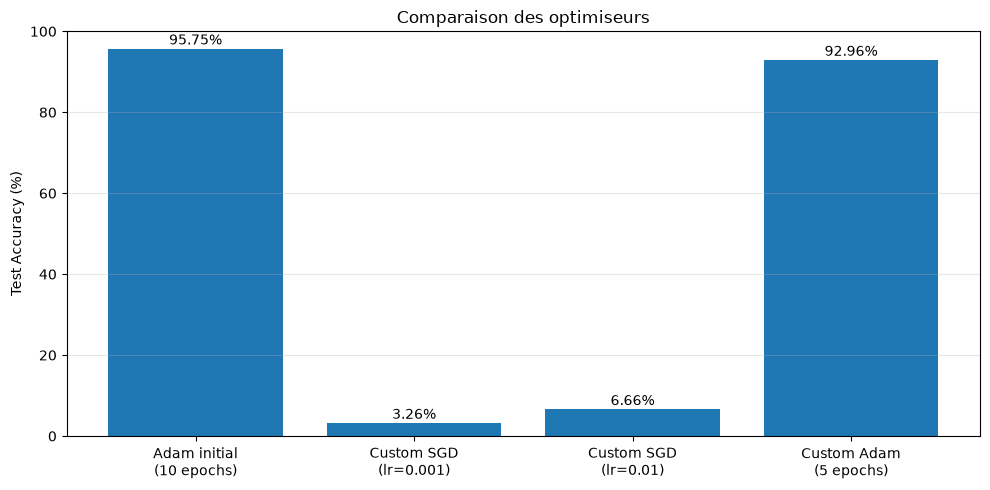

In [38]:

# Comparaison des optimiseurs


optimizer_names = [
    "Adam initial\n(10 epochs)",
    "Custom SGD\n(lr=0.001)",
    "Custom SGD\n(lr=0.01)",
    "Custom Adam\n(5 epochs)"
]

test_accuracies = [
    test_acc,        # Adam initial, 10 epochs
    0.0326,          # Custom SGD, lr=0.001
    0.0666,          # Custom SGD, lr=0.01
    test_acc_adam    # Custom Adam, 5 epochs
]

test_losses = [
    test_loss,
    3.4977,
    3.4884,
    test_loss_adam
]

print(f"{'Optimiseur':<25} {'Test Loss':>12} {'Test Accuracy':>16}")
print("-" * 55)

for name, loss_value, accuracy in zip(
    optimizer_names, test_losses, test_accuracies
):
    print(
        f"{name.replace(chr(10), ' '):<25} "
        f"{loss_value:>12.4f} "
        f"{accuracy * 100:>15.2f}%"
    )

assert len(test_accuracies) == 4
assert all(0 <= acc <= 1 for acc in test_accuracies)

plt.figure(figsize=(10, 5))
bars = plt.bar(optimizer_names, np.array(test_accuracies) * 100)

plt.ylabel("Test Accuracy (%)")
plt.title("Comparaison des optimiseurs")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

for bar, accuracy in zip(bars, test_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy * 100:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [41]:

# Optimiseur SGD avec Momentum


class CustomSGDMomentum:

    def __init__(self, parameters, lr=0.01, momentum=0.9):
        self.parameters = list(parameters)
        self.lr = lr
        self.momentum = momentum

        self.velocity = [
            torch.zeros_like(param)
            for param in self.parameters
        ]

        assert self.lr > 0
        assert 0 <= self.momentum < 1
        assert len(self.parameters) > 0

    def zero_grad(self):
        for param in self.parameters:
            if param.grad is not None:
                param.grad.zero_()

    def step(self):
        with torch.no_grad():
            for i, param in enumerate(self.parameters):
                if param.grad is not None:
                    self.velocity[i] = (
                        self.momentum * self.velocity[i]
                        + param.grad
                    )

                    param -= self.lr * self.velocity[i]




In [42]:

# LeNet-5 avec Custom SGD + Momentum


MOMENTUM_EPOCHS = 5

model_momentum = LeNet5(
    num_classes=N_CLASSES,
    in_channels=N_CHANNELS
).to(device)

criterion_momentum = nn.CrossEntropyLoss()

optimizer_momentum = CustomSGDMomentum(
    model_momentum.parameters(),
    lr=0.01,
    momentum=0.9
)

history_momentum = train_model(
    model=model_momentum,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_momentum,
    optimizer=optimizer_momentum,
    epochs=MOMENTUM_EPOCHS,
    device=device
)

test_loss_momentum, test_acc_momentum = evaluate(
    model_momentum,
    test_loader,
    criterion_momentum,
    device
)

assert len(history_momentum["train_loss"]) == MOMENTUM_EPOCHS
assert np.isfinite(test_loss_momentum)
assert 0 <= test_acc_momentum <= 1

print("\n===== SGD + MOMENTUM =====")
print(f"Test Loss     : {test_loss_momentum:.4f}")
print(f"Test Accuracy : {test_acc_momentum * 100:.2f}%")

Epoch [01/5] | Train Loss: 3.4952 | Train Acc: 0.0336 | Val Loss: 3.4867 | Val Acc: 0.0368
Epoch [02/5] | Train Loss: 3.2308 | Train Acc: 0.1842 | Val Loss: 2.2280 | Val Acc: 0.4349
Epoch [03/5] | Train Loss: 1.3064 | Train Acc: 0.7053 | Val Loss: 0.7927 | Val Acc: 0.8200
Epoch [04/5] | Train Loss: 0.6323 | Train Acc: 0.8509 | Val Loss: 0.5207 | Val Acc: 0.8697
Epoch [05/5] | Train Loss: 0.4484 | Train Acc: 0.8910 | Val Loss: 0.4145 | Val Acc: 0.8930

===== SGD + MOMENTUM =====
Test Loss     : 0.4068
Test Accuracy : 89.77%


In [46]:


os.makedirs("results", exist_ok=True)

# Sauvegarder le meilleur modèle obtenu
torch.save(
    model.state_dict(),
    os.path.join("results", "lenet5_best_adam.pth")
)

# Tableau comparatif
results = [
    ["Adam initial", 10, 0.1491, 0.9575],
    ["Custom SGD lr=0.001", 5, 3.4977, 0.0326],
    ["Custom SGD lr=0.01", 5, 3.4884, 0.0666],
    ["Custom Adam", 5, test_loss_adam, test_acc_adam],
    ["Custom SGD + Momentum", 5,
     test_loss_momentum, test_acc_momentum]
]

csv_path = os.path.join("results", "optimizer_comparison.csv")

with open(csv_path, "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow([
        "Optimizer",
        "Epochs",
        "Test_Loss",
        "Test_Accuracy"
    ])
    writer.writerows(results)

assert os.path.isfile(
    os.path.join("results", "lenet5_best_adam.pth")
)
assert os.path.isfile(csv_path)


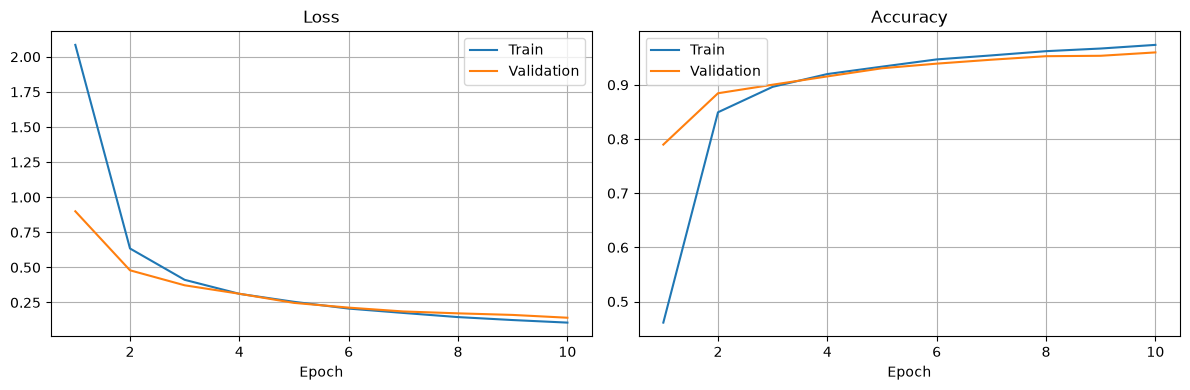

In [48]:



os.makedirs("results", exist_ok=True)

# 1. Sauvegarder le meilleur modèle déjà entraîné
torch.save(
    model.state_dict(),
    "results/lenet5_best_adam.pth"
)

# 2. Sauvegarder les courbes du premier entraînement
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs_range = range(1, len(history["train_loss"]) + 1)

axes[0].plot(epochs_range, history["train_loss"], label="Train")
axes[0].plot(epochs_range, history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_range, history["train_acc"], label="Train")
axes[1].plot(epochs_range, history["val_acc"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
fig.savefig("results/learning_curves.png", dpi=150)
plt.show()
plt.close(fig)

# 3. Sauvegarder la matrice de confusion calculée
np.savetxt(
    "results/confusion_matrix.csv",
    cm,
    delimiter=",",
    fmt="%d"
)

# 4. Sauvegarder les résultats comparatifs
results = [
    ["Adam initial", 10, test_loss, test_acc],
    ["Custom SGD lr=0.001", 5, 3.4977, 0.0326],
    ["Custom SGD lr=0.01", 5, 3.4884, 0.0666],
    ["Custom Adam", 5, test_loss_adam, test_acc_adam],
    ["Custom SGD + Momentum", 5,
     test_loss_momentum, test_acc_momentum]
]

with open(
    "results/optimizer_comparison.csv",
    "w",
    newline="",
    encoding="utf-8"
) as file:
    writer = csv.writer(file)
    writer.writerow([
        "Optimizer", "Epochs", "Test_Loss", "Test_Accuracy"
    ])
    writer.writerows(results)

# 5. Vérifications
required_files = [
    "results/lenet5_best_adam.pth",
    "results/learning_curves.png",
    "results/confusion_matrix.csv",
    "results/optimizer_comparison.csv"
]

assert all(os.path.isfile(path) for path in required_files)



In [50]:


os.makedirs("results", exist_ok=True)

# 1. Classification Report
report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(N_CLASSES)),
    target_names=[idx_to_class[i] for i in range(N_CLASSES)],
    zero_division=0,
    output_dict=True
)

with open(
    "results/classification_report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(
        classification_report(
            all_labels,
            all_predictions,
            labels=list(range(N_CLASSES)),
            target_names=[idx_to_class[i] for i in range(N_CLASSES)],
            zero_division=0
        )
    )

# 2. Confusion Matrix en image
fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(cm, interpolation="nearest")
ax.set_title("Matrice de confusion - Test")
ax.set_xlabel("Classe prédite")
ax.set_ylabel("Classe réelle")
fig.colorbar(ax.images[0], ax=ax)
fig.tight_layout()
fig.savefig("results/confusion_matrix.png", dpi=150)
plt.close(fig)

# 3. Feature Maps en images
image, label = test_dataset[0]
x = image.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    a1 = F.tanh(model.conv1(x))
    s2 = model.pool1(a1)
    a3 = F.tanh(model.conv2(s2))

fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(a1[0, i].cpu().numpy(), cmap="gray")
    ax.set_title(f"C1 - filtre {i+1}")
    ax.axis("off")

fig.tight_layout()
fig.savefig("results/feature_maps_C1.png", dpi=150)
plt.close(fig)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(a3[0, i].cpu().numpy(), cmap="gray")
    ax.set_title(f"C3 - filtre {i+1}")
    ax.axis("off")

fig.tight_layout()
fig.savefig("results/feature_maps_C3.png", dpi=150)
plt.close(fig)

# 4. Vérification des fichiers
saved_files = [
    "results/classification_report.txt",
    "results/confusion_matrix.png",
    "results/feature_maps_C1.png",
    "results/feature_maps_C3.png"
]

assert all(os.path.isfile(path) for path in saved_files)

